In [1]:
import pandas as pd

# Load the CSV file and set 'Date' as the index column
df = pd.read_csv("../data/LUCK_clean.csv", index_col="Date", parse_dates=True)

# Verify the shape and preview the data
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (2885, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2015-01-01,97.695258,98.456346,95.326366,95.326366,2289000
2015-01-02,97.744739,98.893979,96.658280,97.990186,1840000
2015-01-05,96.802893,98.561006,96.658284,98.180462,1225500
2015-01-06,95.105658,97.419369,94.508206,96.087463,2505500
2015-01-07,96.546014,97.417458,94.993393,95.105653,2328500


In [2]:
df.loc[:, ["Close"]].iloc[100:103]

,Close
Date,
2015-05-26,84.737732
2015-05-27,85.430316
2015-05-28,85.021234


### Target definition

- **What the model predicts:** whether the next trading day's close is higher than today's close.
- **When the prediction is made:** after today's close.
- **What the model may use:** only today's data and earlier days, never tomorrow's.

**Example from my data:**
- Date 1 close = 84.74, Date 2 close = 85.43, Date 3 close = 85.02
- Label for Date 1 = 1, because Date 2's close is higher than Date 1's close.
- Label for Date 2 = 0, because Date 3's close is not higher than Date 2's close.

In [3]:
import pandas as pd

df = pd.read_csv("../data/LUCK_clean.csv", index_col="Date", parse_dates=True)

df["next_close"] = df["Close"].shift(-1)
df["next_return"] = df["next_close"] / df["Close"] - 1

df = df.dropna(subset=["next_return"]).copy()

df["target"] = (df["next_return"] > 0).astype(int)

cols = ["Close", "next_close", "next_return", "target"]
print(df[cols].head())
print(df[cols].tail())
print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True))

                Close  next_close  next_return  target
Date                                                  
2015-01-01  97.695258   97.744739     0.000506       1
2015-01-02  97.744739   96.802893    -0.009636       0
2015-01-05  96.802893   95.105658    -0.017533       0
2015-01-06  95.105658   96.546014     0.015145       1
2015-01-07  96.546014   97.406042     0.008908       1
                 Close  next_close  next_return  target
Date                                                   
2026-10-05  407.540009  410.339996     0.006870       1
2026-10-06  410.339996  408.239990    -0.005118       0
2026-10-07  408.239990  405.380005    -0.007006       0
2026-10-09  405.380005  399.109985    -0.015467       0
2026-10-12  399.109985  395.950012    -0.007918       0
target
0    1493
1    1391
Name: count, dtype: int64
target
0    0.517684
1    0.482316
Name: proportion, dtype: float64


### Target definition and manual check

**Target (label):** for each trading day, the model predicts whether the next session's close is higher than today's close.

- `next_close` = the next row's close (`shift(-1)`)
- `next_return` = next_close / Close - 1
- `target = 1` if `next_return > 0` (next close is higher)
- `target = 0` if `next_return <= 0` (next close is lower or the same)

**Last row:** the final date has no next day, so its `next_return` is missing (NaN). It is removed before the target is built, because `NaN > 0` would silently label it 0. This leaves 2,884 rows.

**Manual check (first 5 and last 5 rows):**
- The first row's `next_close` equals the second row's `Close`, so the alignment is right.
- Rows where `next_close` is higher than `Close` have target 1, and the others have target 0.
- The last row shown is 2026-10-12, because the final date (2026-10-13) has no tomorrow.

**Class balance:** 1,493 days are 0 (51.8%) and 1,391 are 1 (48.2%). "Always predict not-up" would score about 51.8% over the whole period, so that's the baseline to beat (the exact value will be chosen from the training data only).

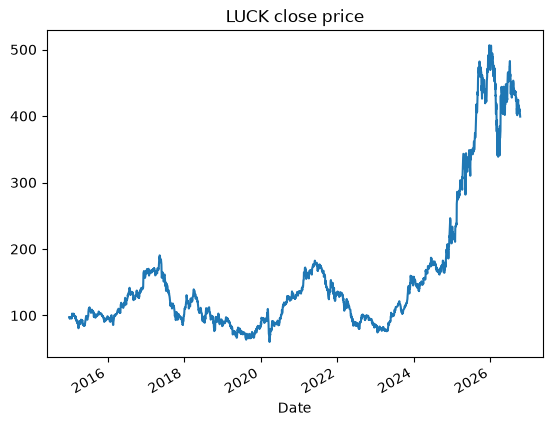

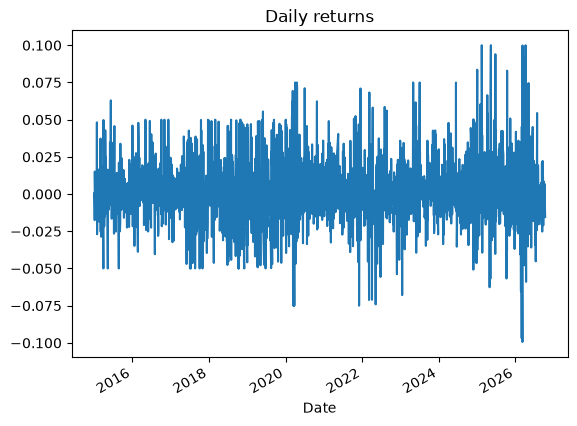

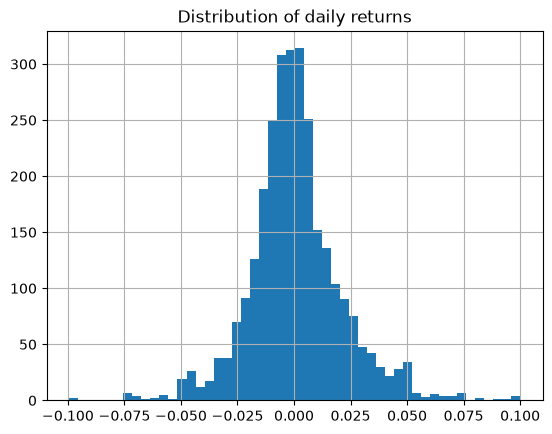

count    2883.000000
mean        0.000701
std         0.020670
min        -0.099389
25%        -0.010375
50%        -0.000548
75%         0.010395
max         0.100010
Name: ret, dtype: float64
Date
2015    0.471545
2016    0.516260
2017    0.451613
2018    0.463115
2019    0.465306
2020    0.496000
2021    0.446721
2022    0.443548
2023    0.540984
2024    0.491803
2025    0.527197
2026    0.473118
Name: target, dtype: float64


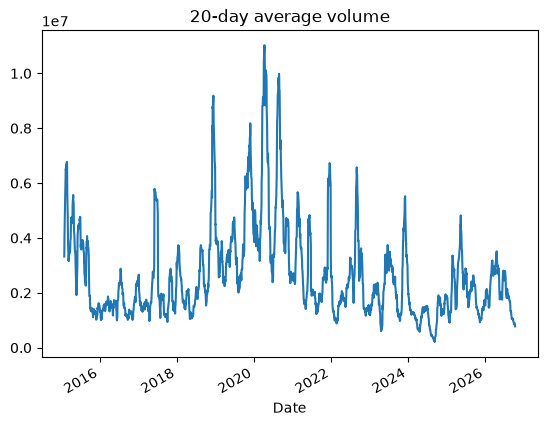

Date
2025-05-12    0.100010
2025-02-14    0.100004
2026-04-08    0.099995
2026-03-10    0.099835
2025-06-24    0.093981
Name: ret, dtype: float64
Date
2026-03-09   -0.099389
2026-03-02   -0.096902
2021-12-02   -0.074995
2020-03-24   -0.074993
2020-03-18   -0.074989
Name: ret, dtype: float64
0.10768819767055067


In [4]:
import matplotlib.pyplot as plt

df["ret"] = df["Close"].pct_change()

df["Close"].plot(title="LUCK close price")
plt.show()

df["ret"].plot(title="Daily returns")
plt.show()

df["ret"].hist(bins=50)
plt.title("Distribution of daily returns")
plt.show()

print(df["ret"].describe())

print(df.groupby(df.index.year)["target"].mean())

df["Volume"].rolling(20).mean().plot(title="20-day average volume")
plt.show()

print(df["ret"].nlargest(5))
print(df["ret"].nsmallest(5))

print(df["ret"].corr(df["ret"].shift(1)))

### Observations

1. **Class balance:** 48.2% of days are up and 51.8% are down or flat. The up share by year ranges from 44.4% (2022) to 54.1% (2023), so the most common class is not stable over time. The majority baseline will be chosen from training data only.
2. **Returns:** the mean daily return is +0.07% but the median is -0.05%, so a few large up days pull the mean up. This is why the price rose about 4x even though fewer than half of the days were up.
3. **Fat tails and price limits:** the middle half of daily returns lies between -1.04% and +1.04%, but extreme days reach about ±10%. The biggest moves sit at the daily price limits (7.5% and 10%), and the returns chart suggests the limit widened over time (about ±5% early, ±7.5% around 2020-23, ±10% in 2025-26). I have not verified the exact dates.
4. **Volatility and volume:** calm and wild periods cluster (2020, 2022 and 2025-26 are wilder). Volume spikes (2018, 2020, 2022) return to normal, so they look like real bursts of trading, not data errors.
5. **Yesterday vs today:** the correlation between today's return and yesterday's is 0.108. This is small but probably not zero, so the previous-direction baseline may be slightly better than chance. It does not show the market is predictable, and it needs testing on unseen data.

In [5]:
df.to_csv("../data/LUCK_target.csv")
print(df.shape)
print(df.columns.tolist())

(2884, 9)
['Close', 'High', 'Low', 'Open', 'Volume', 'next_close', 'next_return', 'target', 'ret']
